In [1]:
!pip install missingno

Defaulting to user installation because normal site-packages is not writeable


In [2]:
# load and explore the datset 
# clean and processes the dataset 
# reduce dimensionality with pca 
# cluseter the track with k means 
# evaluate with elbow and silhoutte analysis 
# visualize and interprest cluester

In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

import os 
import math 
import random 
# import dataclass import dataclass
# from typingList,Tuple,Optional

Random_seed =42
np.random.seed(Random_seed)
random.seed(Random_seed)
# DATA_PATH = os.path.exists(DATA_PATH),f"music-dataset.csv not fpound at {DATA_PATH}"







In [4]:
# raw_df = pd.read_csv(DATA_PATH)
# print(raw_df.shape)
# raw_df.head()

In [5]:
df = pd.read_csv("music-dataset.csv")
df.head()
# df.describe()



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [6]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [7]:
df.shape
# df.dtypes

(114000, 21)

In [8]:
df.info()   #summary of dataframe

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [9]:
# clean and preprocess the dataset 
df.drop_duplicates(inplace = True)   ##remove duplicates


In [10]:
# handling missing values
df.isnull().sum()

# if the val is missing - true
# if the value is present - false
# and sum count the true values in each column 



Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [11]:
print("number of unique values per column")
print(df.nunique())

number of unique values per column
Unnamed: 0          114000
track_id             89741
artists              31437
album_name           46579
track_name           73602
popularity             101
duration_ms          50697
explicit                 2
danceability          1174
energy                2083
key                     12
loudness             19480
mode                     2
speechiness           1489
acousticness          5061
instrumentalness      5346
liveness              1722
valence               1790
tempo                45653
time_signature           5
track_genre            114
dtype: int64


In [15]:
# if numeric column has missing value 
df.fillna(df.mean(numeric_only = True),inplace = True)
            

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [16]:
#if categorical columns have missing value
df.fillna(df.mode().iloc[0],inplace = True)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [17]:
#select numeric feature
numeric_df = df.select_dtypes(include=np.number)
numeric_df.head()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,0,73,230666,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4
1,1,55,149610,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4
2,2,57,210826,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4
3,3,71,201933,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3
4,4,82,198853,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4


In [18]:
# standradize the data 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler_data = scaler.fit_transform(numeric_df)

In [19]:
# Reduce dimensionality using PCA

from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
pca_data = pca.fit_transform(scaler_data)

In [20]:
# create pca daatframe
pca_df = pd.DataFrame(
    pca_data,
    columns = ["PC1","PC2"]
)
pca_df.head()

,PC1,PC2
0,0.793075,0.613477
1,-3.226902,1.157873
2,-1.346183,-0.282283
3,-3.749210,-0.511391
4,-0.881078,0.205328


In [21]:
# cluster the track using k_means
from sklearn.cluster import KMeans
# kmeans = KMeans(
#     n_clusters=3,
#     random_state=42
# )
# clusters = Kmeans.fit_predict(pca_data)
# pca_df["Cluster"]=clusters

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

clusters = kmeans.fit_predict(pca_data)

pca_df["Cluster"] = clusters


In [22]:
# #Evaluate with elbow method 
# wcss = []
# for k in range(1,11):
#     model = KMeans(
#         n_clusters= k,
#         random_state = 42
#     )
#     model.fit(pca_data)
#     wcss.append(model.inertia_)


In [23]:
# print(wcss)
# print(len(wcss))

In [24]:
#Evaluate with elbow method 
wcss = []
for k in range(1,11):
    model = KMeans(
        n_clusters= k,
        random_state = 42
    )
    model.fit(pca_data)
    wcss.append(model.inertia_)

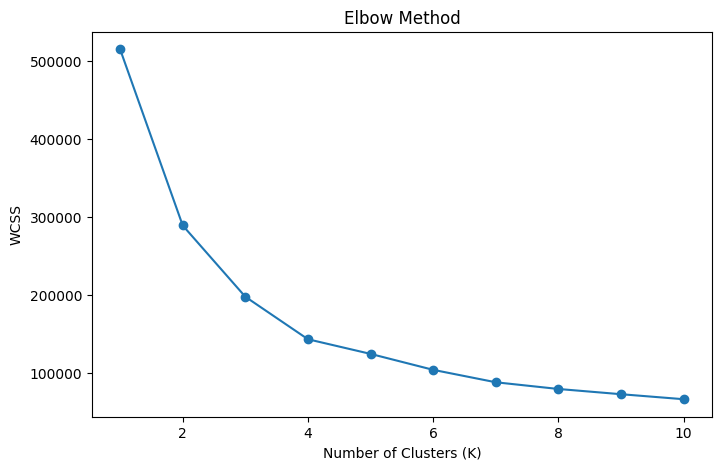

In [25]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [26]:
# eveluate using the silhouette score
from sklearn.metrics import silhouette_score
score = silhouette_score (
    pca_data,
    clusters
)
print("silhouette score:",score)


silhouette score: 0.3764379204978465


In [27]:
# print(clusters)

In [28]:
# visualize the clusters

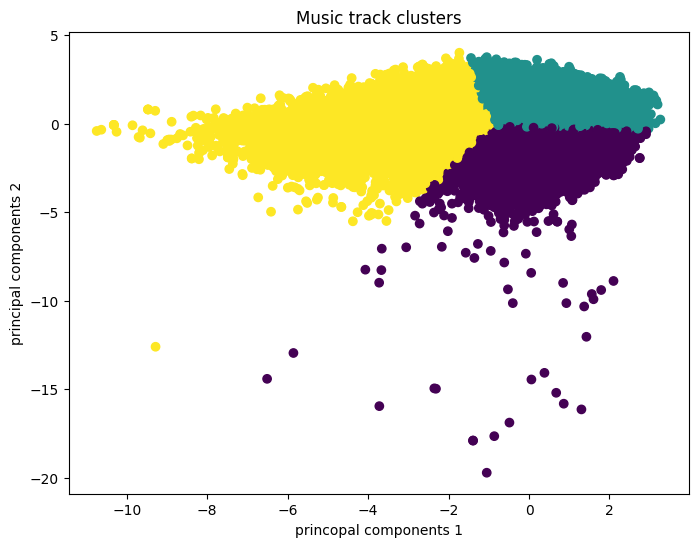

In [29]:
# visualize the clusters
plt.figure(figsize=(8,6))
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Cluster"]
)
plt.xlabel("princopal components 1")
plt.ylabel("principal components 2")
plt.title("Music track clusters")
plt.show()

In [30]:
# view the clusters centers
print(kmeans.cluster_centers_)


[[ 0.61356675 -1.28252911]
 [ 0.75534914  0.79346021]
 [-2.77443599  0.22025012]]


In [31]:
# interpret the clusters
pca_df["Cluster"].value_counts()

Cluster
1    53904
0    37131
2    22965
Name: count, dtype: int64

In [32]:
# calculate the average of clusters
df["Cluster"]=clusters
df.groupby("Cluster").mean(numeric_only=True)

,Unnamed: 0,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
Cluster,,,,,,,,,,,,,,,,
0,48709.127091,32.945921,269697.174490,0.079475,0.488806,0.804038,5.491611,-6.196962,0.572244,0.083110,0.083670,0.232380,0.252273,0.341213,134.648666,3.928739
1,61324.317231,34.604872,204561.889841,0.119082,0.670578,0.685164,5.352645,-6.807252,0.651269,0.097926,0.279550,0.026566,0.202840,0.645472,119.190800,3.983192
2,60252.488831,30.504550,215741.065056,0.016416,0.449314,0.275630,4.911997,-15.000392,0.710951,0.055991,0.771788,0.336562,0.176094,0.286553,108.876680,3.678293


In [33]:
# visualize distributations and relationships for EDA
import matplotlib.pyplot as plt 
import seaborn as sns

# identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols=df.select_dtypes(include=["object","string","category","bool"]).columns.tolist()

print("numeric columns:",numeric_cols)
print("categorical columns:",categorical_cols)

numeric columns: ['Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'Cluster']
categorical columns: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']


plotting histograms for numeric columns


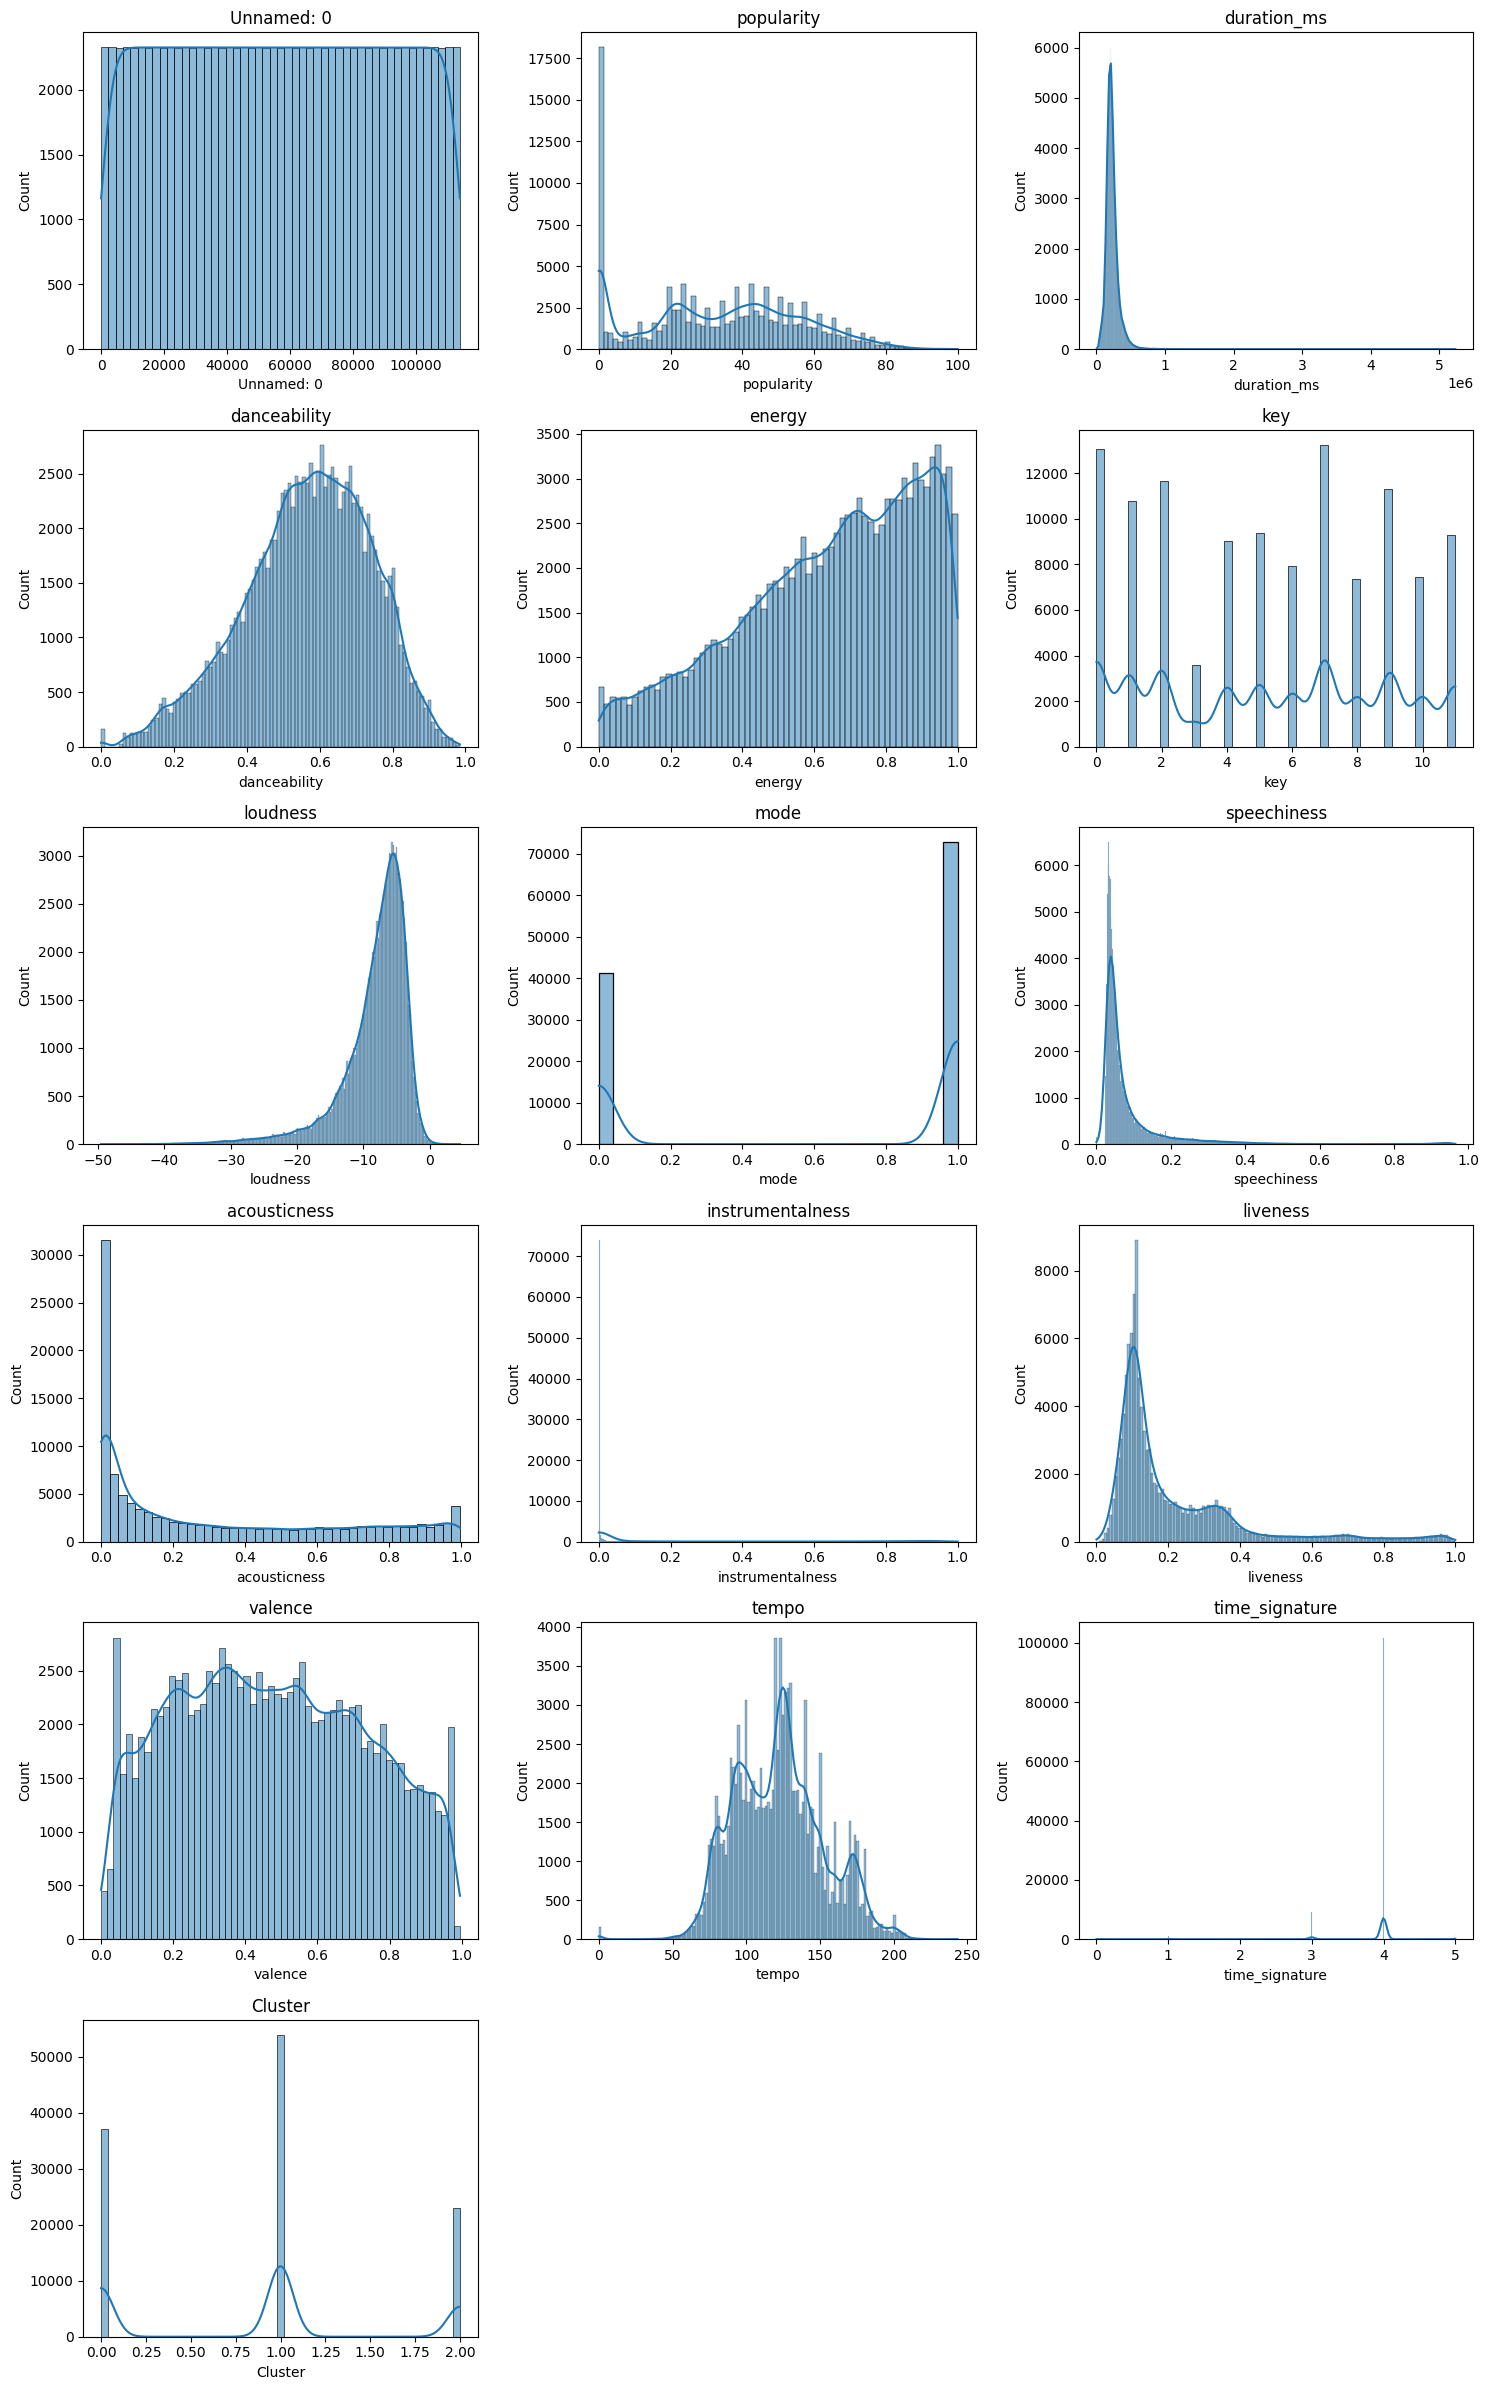

plotting boxplot for numeric columns


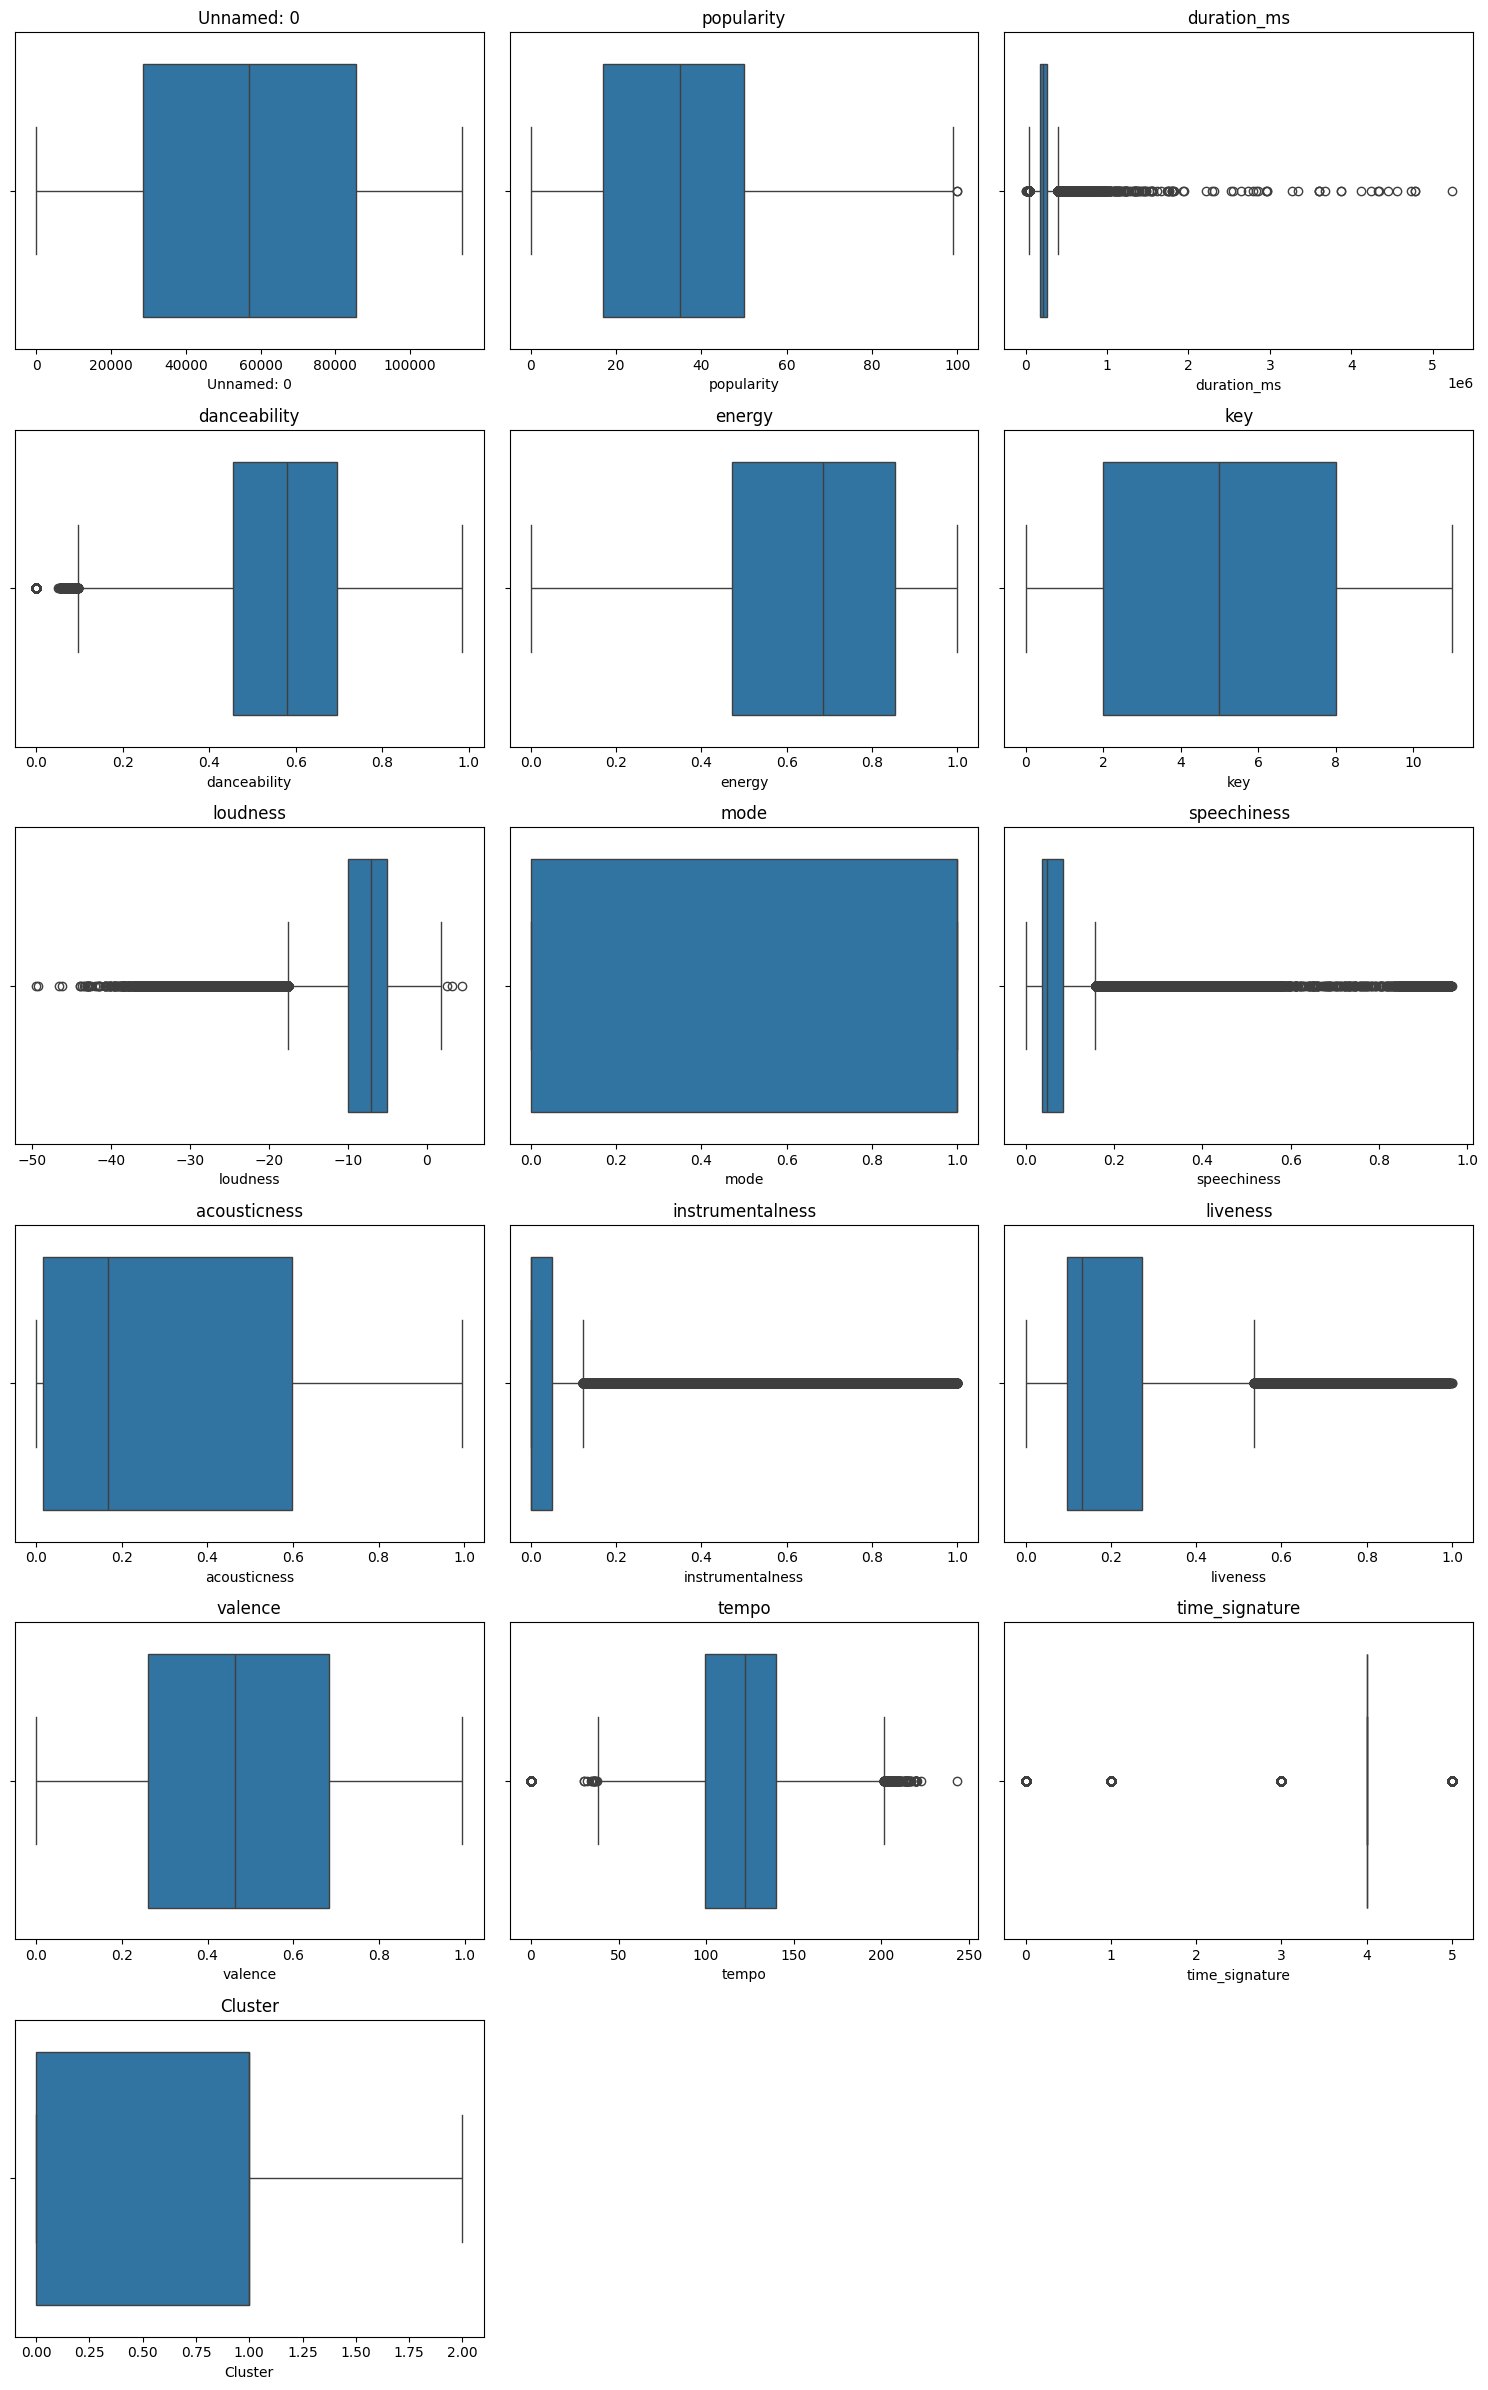

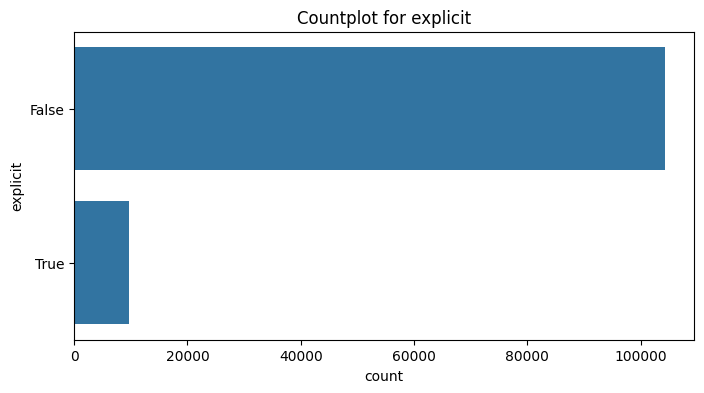

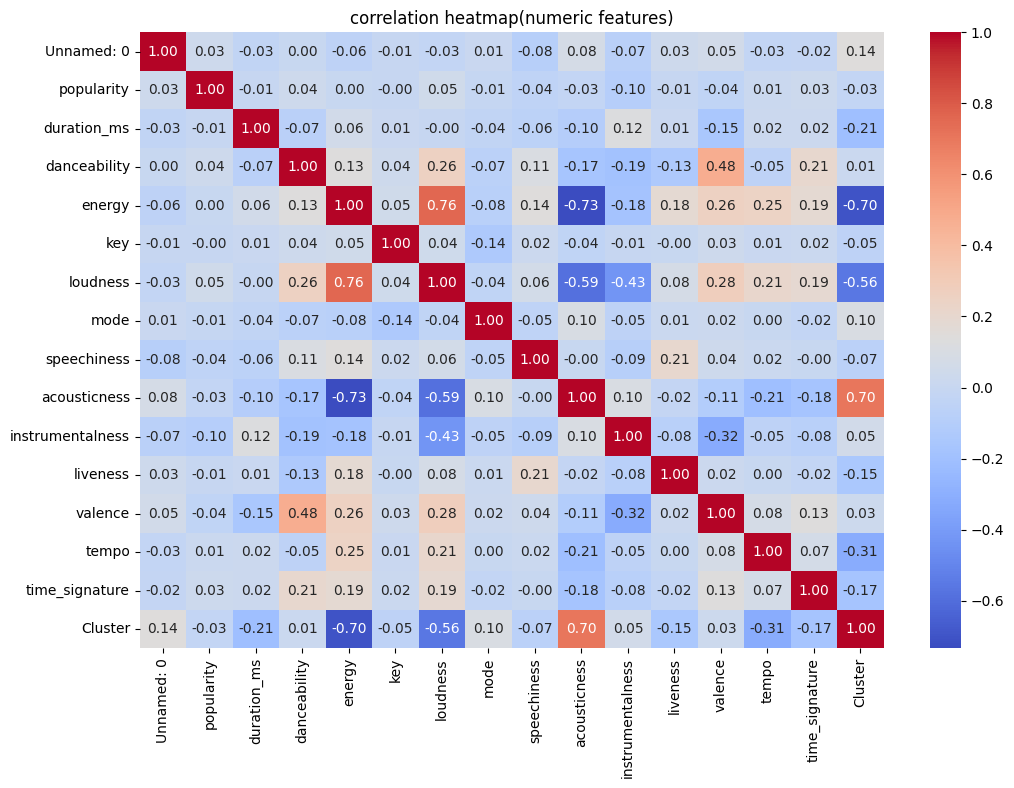

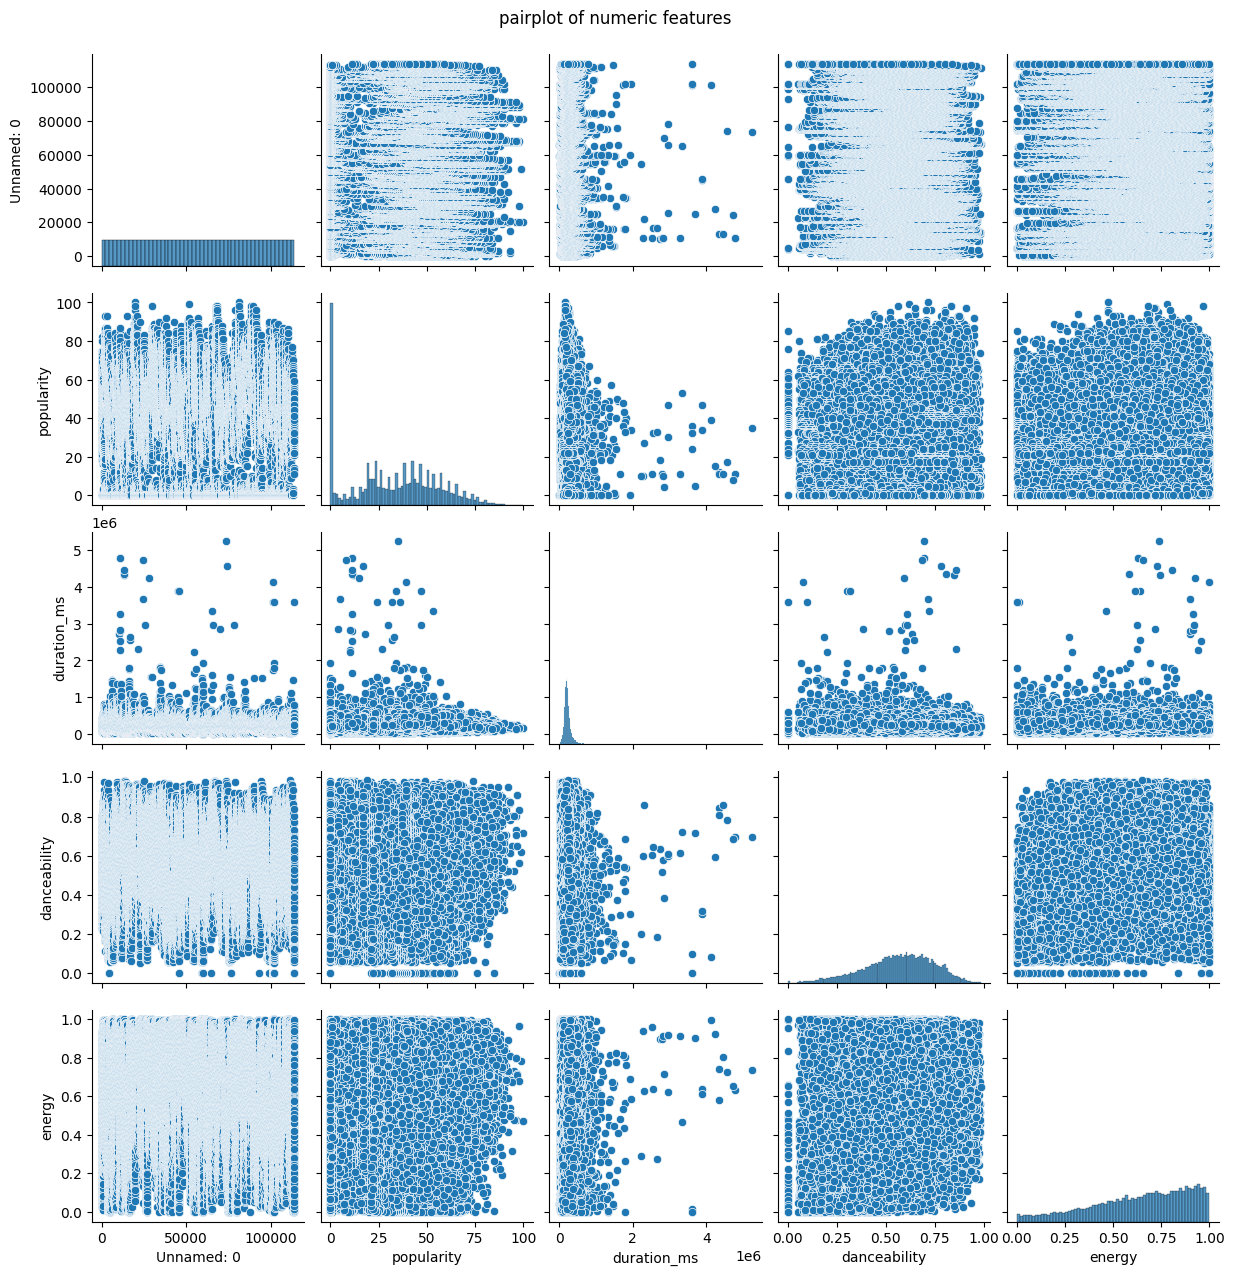


Missing values summary:
Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
Cluster             0
dtype: int64


In [34]:
# histograms for numeric columns
print("plotting histograms for numeric columns")
n_num = len(numeric_cols)
ncols=3
nrows = (n_num + ncols-1) //ncols
fig,axes = plt.subplots(nrows,ncols,figsize=(5*ncols,4*nrows))
axes= axes.flatten()
for i,col in enumerate(numeric_cols):
    sns.histplot(df[col].dropna(),kde= True,ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1,len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()


# boxplot for numeric columns (to spot outlier)
print("plotting boxplot for numeric columns")
fig,axes = plt.subplots(nrows,ncols,figsize=(5*ncols,4*nrows))
axes= axes.flatten()
for i,col in enumerate(numeric_cols):
    sns.boxplot(x=df[col],ax=axes[i])
    axes[i].set_title(col)
for j in range(i+1,len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

# count plot for categorical columns(to spot outliers)
for col in categorical_cols:
    n_unique =df[col].nunique()
    if n_unique < 30:
        plt.figure(figsize=(8,4))
        sns.countplot(y=df[col],order=df[col].value_counts().index)
        plt.title(f"Countplot for {col}")
        plt.show()

# correlation heatmap for numeric columns

if len(numeric_cols)>1:
    plt.figure(figsize=(12,8))
    corr=df[numeric_cols].corr()
    sns.heatmap(corr,annot=True,fmt =".2f",cmap="coolwarm")
    plt.title("correlation heatmap(numeric features)")
    plt.show()


# pairplot for a subset of numeric columns (if not too many)
if len(numeric_cols)> 1:
    subset_cols = numeric_cols[:5]   # limit to 5 for readability
    sns.pairplot(df[subset_cols].dropna())
    plt.suptitle("pairplot of numeric features",y=1.02)  #(suptitle stands for super title which add a titile to the entire fig not just a single subplot)
    plt.show()


# handling missing values
print("\nMissing values summary:")
print(df.isnull().sum())






    


No missing value detected in any column.


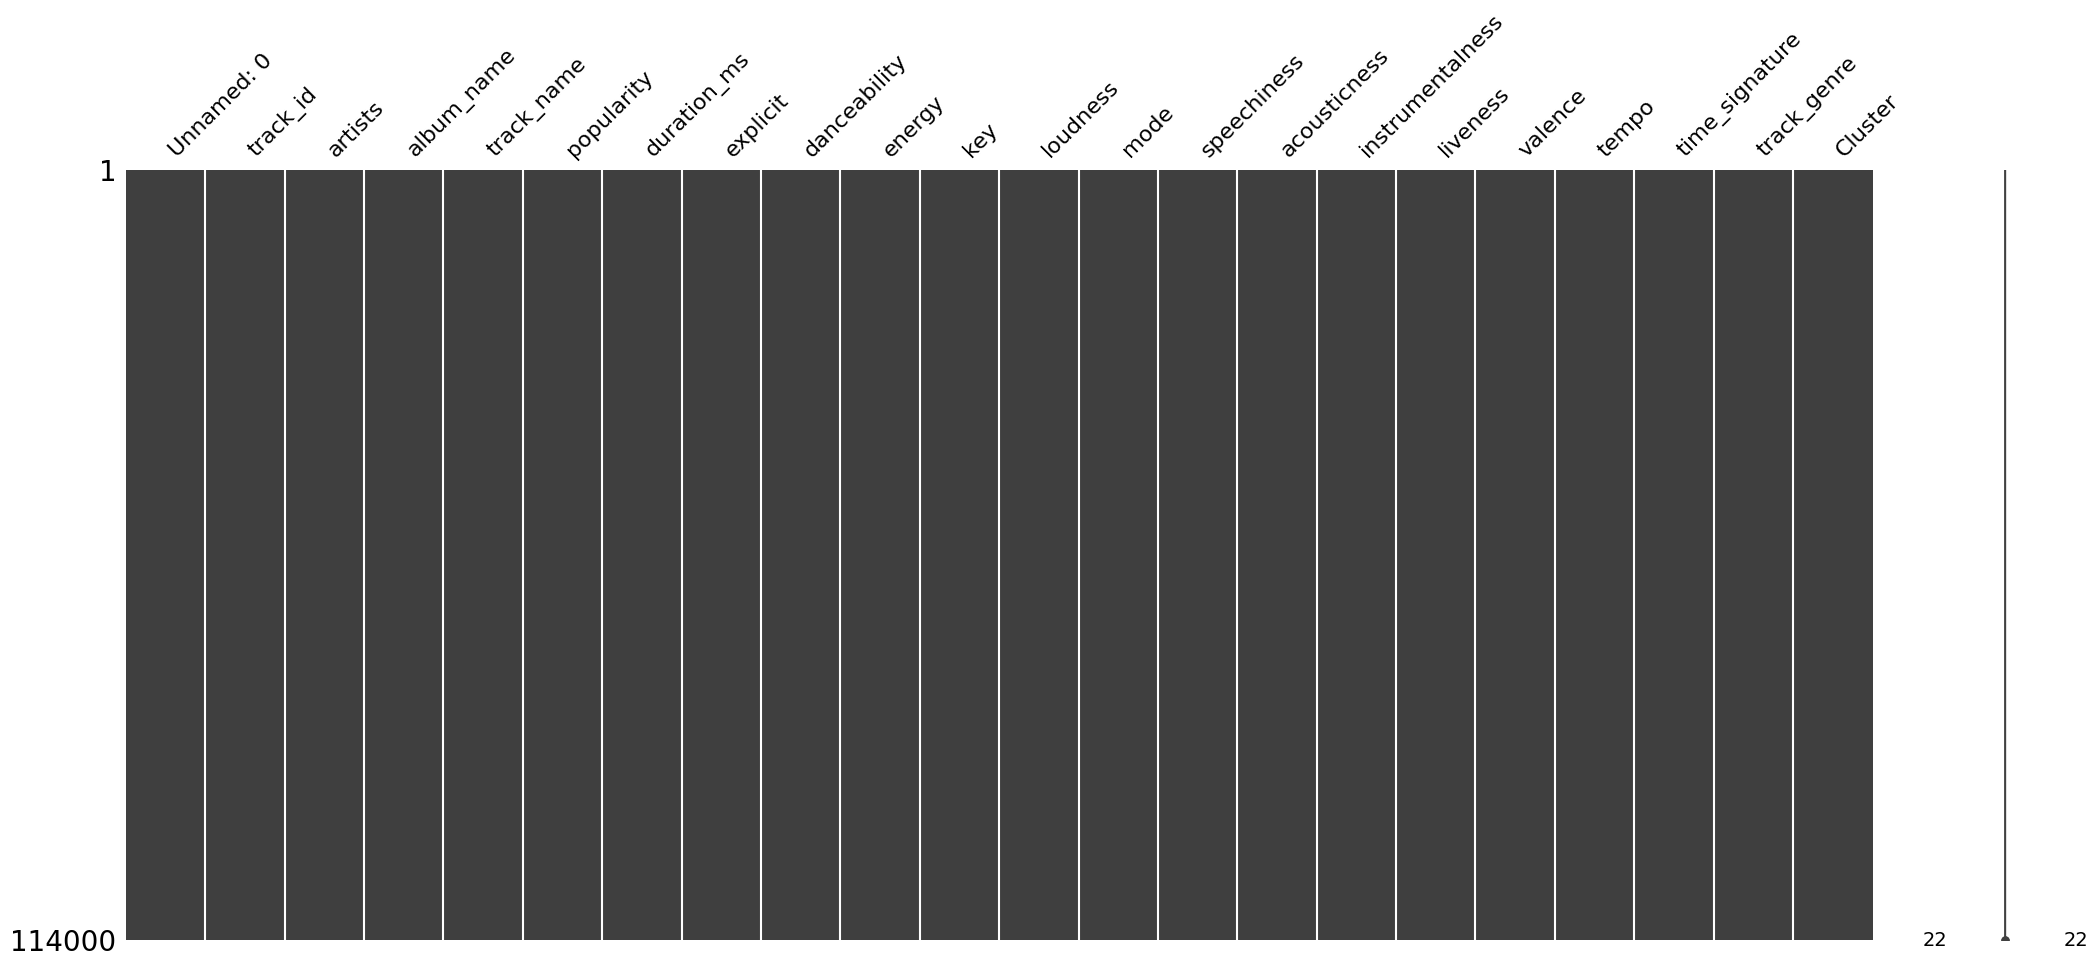

In [35]:
# missing value and visualize thme for better understanding 
import seaborn as sns
import matplotlib.pyplot as plt 

# barplot for missing value per column 
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts >0]
if not missing_counts.empty:
    plt.figure(figsize=(10,5))
    sns.barplot(x=missing_counts.index, y= missing_counts.values)
    plt.ylabel("Number of missing values")
    plt.title("Missing values per column")
    plt.xticks(rotation=45,ha="right")
    plt.show()

else:
    print("No missing value detected in any column.")

# 2 visualize missingness as a matrix (if missingness is available)
try:
    import missingno as msno
    msno.matrix(df)
    plt.show()

except ImportError:
    print("missingness not installed;skipping missingness matrix plot.")

#3 print column with the most missing values
if not missing_counts.empty:
    print("\nColumns with most missing values:")
    print(missing_count.sort_values(ascending=False))

#  in this no missing value is detected in any column because this usually happens if
# already removed missing values earlier, for example: we use df= df.dropna()   or df= df.fillna()


In [36]:
# handling missing value in dataset 
# strategy
# for numeric column fill missing vvalues with the median(robust to outlier)
# for categorical value fill missing value with the mode (most frequent value)

from pandas.api.types import is_numeric_dtype

filled_df = df.copy()
for col in df.columns:
    if df[col].isnull().any():
        if is_numeric_dtype(df[col]):
            median_val = df[col].median()
            filled_df[col] = df[col].fillna(median_val)
    else:
        mode_val = df[col].mode()
        if not mode_val.empty:
            filled_df[col] = df[col].fillna(mode_val[0])
        else:

# if the mode is empty (all values are NaN) ,fill with placeholder
            filled_df[col] = df[col].fillna("Unknown")

# use filled_df for further analysis

print("missing values after imputation:")
print(filled_df.isnull().sum()[filled_df.isnull().sum()>0])



    

missing values after imputation:
Series([], dtype: int64)


In [37]:
#  if we have the missing value that we use mode
# in this dataset also have single single missing value but i use isnull so thats why the above code will not show mme the graph of missing value 
# an if we have missing value than we fill this value with the mode.


# drop columm that have all unique values(likely id columns)
# select features based on the cardinality (exclude with all unique values,eg  ids)

# heuristics for id_like column(keep inside)

ID_LIKE ={"unnamed :0","id","track_id","song_id","url"}

# exclude column with all unique values(likely ids)
unique_counts= filled_df.nunique()
n_rows= len(filled_df)

#exclude column where every value is unique,or in id_like 
exclude_cols =[ c for c in filled_df.columns if unique_counts[c] == n_rows or c.lower() in ID_LIKE]

# keep columns that are not exclude 
candidate_cols = [c for c in filled_df.columns if c not in exclude_cols]

#optionally,further exclude columns with vary high cardinality (e.g. >985 unique)
# candiate_cols = [c for c in cadidates_cols if unique_counts[c]< 0.9 * n_cols]

print("Excluded columns (likely ids or all_unique):",exclude_cols)
print("candidate feature column:",candidate_cols)

#drop rows with missing values in these columns
clean_df = filled_df[candidate_cols].dropna(subset=candidate_cols).reset_index(drop= True)

clean_df= clean_df.drop_duplicates()
clean_df.shape



Excluded columns (likely ids or all_unique): ['Unnamed: 0', 'track_id']
candidate feature column: ['artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'Cluster']


(113423, 20)

In [38]:
clean_df.columns

Index(['artists', 'album_name', 'track_name', 'popularity', 'duration_ms',
       'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode',
       'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre', 'Cluster'],
      dtype='str')

In [39]:
clean_df["album_name"].value_counts()

album_name
Feliz Cumpleaños con Perreo                                                                      180
Alternative Christmas 2022                                                                       157
Metal                                                                                            143
Halloween con perreito                                                                           122
Halloween Party 2022                                                                             111
                                                                                                ... 
The Light Meets The Dark                                                                           1
HUMAN (Deluxe) [Live]                                                                              1
#20 Sueños Vividos - Música Intrumental Suave 2018 para Dormir Bien y Relajarse Profundamente      1
Frecuencias Álmicas en 432hz (Solo Piano)                                       

In [40]:
# print(df.isnull().sum())

In [41]:
# print(df.isnull().sum().sum())

In [42]:
clean_df["track_name"].value_counts()

track_name
Run Rudolph Run                   152
Halloween                          88
Frosty The Snowman                 80
Little Saint Nick - 1991 Remix     74
Christmas Time                     72
                                 ... 
Frecuencia Álmica, Pt. 4            1
Sleep My Little Boy                 1
Water Into Light                    1
Miss Perfumado                      1
Barbincor                           1
Name: count, Length: 73602, dtype: int64

In [43]:
clean_df["explicit"].value_counts()

explicit
False    103726
True       9697
Name: count, dtype: int64

In [44]:
# here we convert all non-numeric columns into numeric values because machine learning algorithms (like PCA and K-Means) only work with numbers.

from sklearn.preprocessing import OrdinalEncoder
# sklearn.preprocessing is used to convert the categorical (text) into the numeric values.


# identfy the non numeric columns in candidate_cols
non_numeric_cols = [c for c in candidate_cols if not is_numeric_dtype(clean_df[c])]
print("non_numeric_cols:",non_numeric_cols)

# Transform boolean columns to numeric(0/1)
for col in clean_df.select_dtypes(include=["bool"]).columns:
    clean_df[col] = clean_df[col].astype(int)

# apply ordinalEncoder to non_numeric columns
if non_numeric_cols:
    encoder = OrdinalEncoder()
    clean_df[non_numeric_cols] = encoder.fit_transform(clean_df[non_numeric_cols])

# now all columns in clean _df[candidates_cols] are numeric

non_numeric_cols: ['artists', 'album_name', 'track_name', 'track_genre']


In [45]:
clean_df.head(5)

,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,Cluster
0,10357.0,8089.0,11735.0,73,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,0.0,1
1,3287.0,14786.0,22522.0,55,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,0.0,2
2,12397.0,39153.0,60769.0,57,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,0.0,2
3,14839.0,8569.0,9574.0,71,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,0.0,2
4,5255.0,16889.0,25683.0,82,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,0.0,1


In [46]:
# feature scaling 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clean_df)
X_scaled[:3]

array([[-0.59346539, -1.07605301, -1.17956701,  1.78002884,  0.02411295,
        -0.30575593,  0.62795483, -0.72172418, -1.21057932,  0.29867466,
        -1.32663194,  0.55105983, -0.84917778, -0.50369799,  0.75803755,
         0.92871841, -1.14304896,  0.22166216, -1.71697066,  0.17659473],
       [-1.37255564, -0.57760109, -0.66414705,  0.97175391, -0.73731951,
        -0.30575593, -0.84839306, -1.89688721, -1.21057932, -1.79414941,
         0.75378857, -0.07936475,  1.83743474, -0.50368328, -0.59118768,
        -0.79942597, -1.49097511,  0.22166216, -1.71697066,  1.57601512],
       [-0.36866425,  1.23601363,  1.16335523,  1.06156223, -0.16226215,
        -0.30575593, -0.74458735, -1.12805174, -1.4914988 , -0.29750785,
         0.75378857, -0.2740686 , -0.31354231, -0.50370126, -0.50718922,
        -1.36647335, -1.52957796,  0.22166216, -1.71697066,  1.57601512]])

Fitting KMeans with k=2
Fitting KMeans with k=3


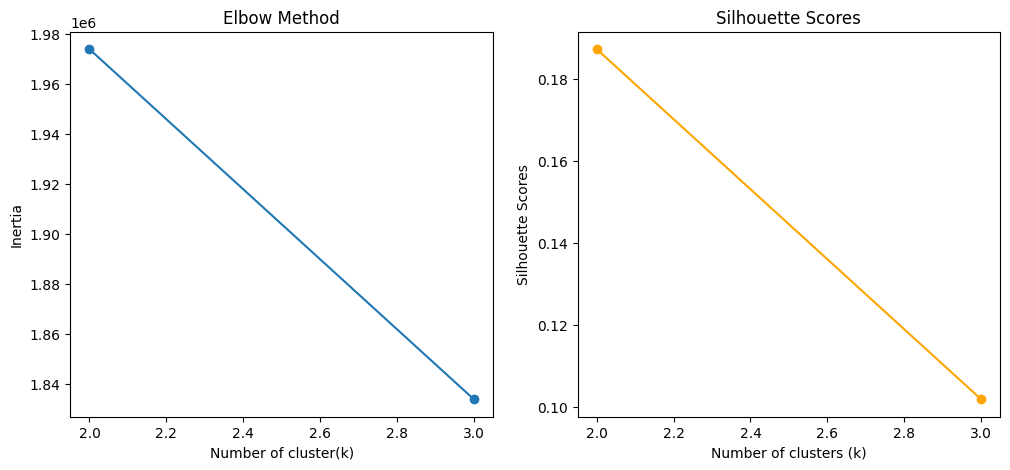

In [47]:
# K-mean
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# choosing optimal number of clusters
inertia = []
sil_scores = []
K = range(2,4)    ##trying k from 2 to 10

for k in K:
    print(f"Fitting KMeans with k={k}")
    kmeans = KMeans(n_clusters=k,random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled,kmeans.labels_))

# plot Elbow Method
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K,inertia,marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of cluster(k)")
plt.ylabel("Inertia")

# plot Silhoutte Score
plt.subplot(1,2,2)
plt.plot(K,sil_scores,marker="o",color="orange")
plt.title("Silhouette Scores")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Scores")
plt.show()


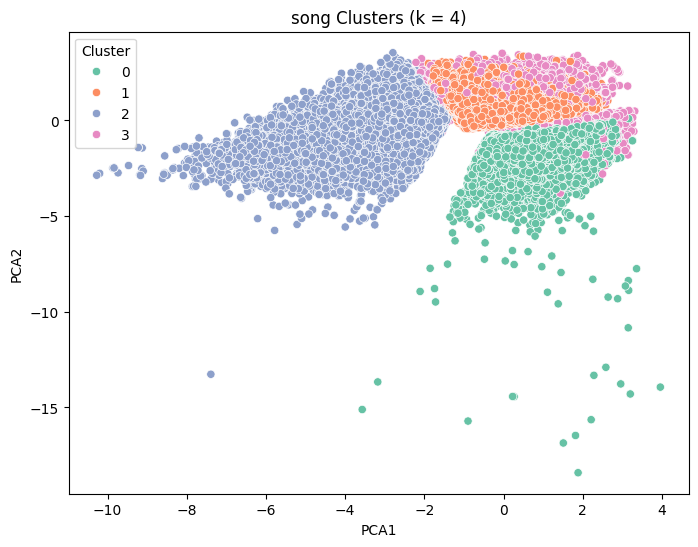


Cluster Feature Mean:


,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,PCA1,PCA2
Cluster,,,,,,,,,,,,,,,,,,,,,
0,15798.738883,22494.819093,35976.561179,32.887605,272601.862093,0.000323,0.490889,0.798554,5.508715,-6.266967,...,0.075559,0.083501,0.241103,0.248839,0.344126,134.797354,3.930165,48.635335,1.180524,-1.440796
1,15706.523216,22018.519819,36046.688648,34.395597,206717.031549,0.000000,0.664239,0.686941,5.344260,-6.812541,...,0.079839,0.281516,0.029220,0.199834,0.658129,119.494617,3.981423,61.959067,0.443847,0.910824
2,15802.938787,23721.465350,38116.459408,30.636969,216050.419954,0.003172,0.448185,0.274309,4.912202,-14.994699,...,0.051691,0.772432,0.340372,0.173639,0.286099,108.986225,3.681516,60.037040,-3.213100,-0.096766
3,15584.189454,22578.802682,35904.627445,36.200141,204169.281508,0.969449,0.635699,0.723244,5.355818,-6.578171,...,0.213596,0.225374,0.047808,0.248371,0.471867,121.381142,3.951200,49.747530,1.093144,0.835372


In [50]:
# choose k based on plots 
best_k = 4 
kmeans = KMeans(n_clusters = best_k,random_state = 42)
clean_df["Cluster"] = kmeans.fit_predict(X_scaled)

#  dimensionality reduction for visualization
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
clean_df["PCA1"] = X_pca[:,0]
clean_df["PCA2"] = X_pca[:,1]

#  plot clusters
plt.figure(figsize=(8,6))
sns.scatterplot(data= clean_df , x="PCA1", y="PCA2",hue="Cluster",palette="Set2")
plt.title(f"song Clusters (k = {best_k})")
plt.show()

# analyze cluster
cluster_summary = clean_df.groupby("Cluster").mean()
print("\nCluster Feature Mean:")
display(cluster_summary)


In [55]:
# use DBscan 
# and shilhotte score 
# use the another way also to find the silhouette score 




In [1]:
import numpy as np
import tensorflow as tf

ModuleNotFoundError: No module named 'tensorflow'